# Setup check

This notebook checks that your computer is ready for the school's notebooks. Run it from its page with **Run on this computer**, as the reading *Setting up your computer* of this topic explains, then run its cells in order. The last cell prints *Setup complete*.

Its packages are pinned in `requirements.txt`, which lies in this notebook's folder. Install them once, in that folder, with the environment you made for the school active:

```
pip install -r requirements.txt
```

## Python

Which Python runs this notebook. The school's notebooks are pinned for Python 3.11 to 3.13, run from a virtual environment or a conda environment.

In [1]:
import platform
import sys
from pathlib import Path

if sys.prefix != sys.base_prefix:
    environment = "a virtual environment"
elif (Path(sys.prefix) / "conda-meta").is_dir():
    environment = "a conda environment"
else:
    environment = "no environment of its own"

print("Python", platform.python_version(), "on", platform.system(), platform.machine())
print("Runs in", environment)
if not (3, 11) <= sys.version_info[:2] <= (3, 13):
    print("Warning: this is not Python 3.11 to 3.13; the school's pinned packages may not install.")

Python 3.13.17 on Linux x86_64
Runs in a virtual environment


## Packages

The cell reads `requirements.txt` from this notebook's folder, which shows that the notebook's files reached your computer, and compares each pinned package with the version installed.

In [2]:
from importlib.metadata import PackageNotFoundError, version

pins = {}
for line in Path("requirements.txt").read_text().splitlines():
    line = line.strip()
    if line and not line.startswith("#"):
        name, _, pinned = line.partition("==")
        pins[name] = pinned

missing = []
for name, pinned in pins.items():
    try:
        installed = version(name)
    except PackageNotFoundError:
        missing.append(name)
        print(f"{name}: not installed (requirements.txt pins {pinned})")
        continue
    note = "as pinned" if installed == pinned else f"requirements.txt pins {pinned}"
    print(f"{name} {installed}, {note}")

if missing:
    raise ModuleNotFoundError(
        "Not installed in this Python: " + ", ".join(missing) + ". "
        "In this notebook's folder, run: pip install -r requirements.txt"
    )

numpy 2.4.6, as pinned
pandas 3.1.0, as pinned
matplotlib 3.11.2, as pinned


## A table

Logistic growth of a bacterial population, $N(t) = K / (1 + (K/N_0 - 1)\,e^{-rt})$, over 24 hours for three growth rates $r$, computed with numpy and kept in a pandas table. The table shows every fourth hour.

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

hours = np.linspace(0, 24, 49)  # every 30 minutes
capacity, start = 1.0, 0.01  # carrying capacity K and starting density N0, relative units
growth = pd.DataFrame(
    {
        f"r = {rate} per hour": capacity / (1 + (capacity / start - 1) * np.exp(-rate * hours))
        for rate in (0.3, 0.5, 0.8)
    },
    index=pd.Index(hours, name="hours"),
)
growth.iloc[::8].round(3)

,r = 0.3 per hour,r = 0.5 per hour,r = 0.8 per hour
hours,,,
0.0,0.010,0.010,0.010
4.0,0.032,0.069,0.199
8.0,0.100,0.355,0.859
12.0,0.270,0.803,0.993
16.0,0.551,0.968,1.000
20.0,0.803,0.996,1.000
24.0,0.931,0.999,1.000


## A figure

The same curves drawn with matplotlib. The figure appears below the cell.

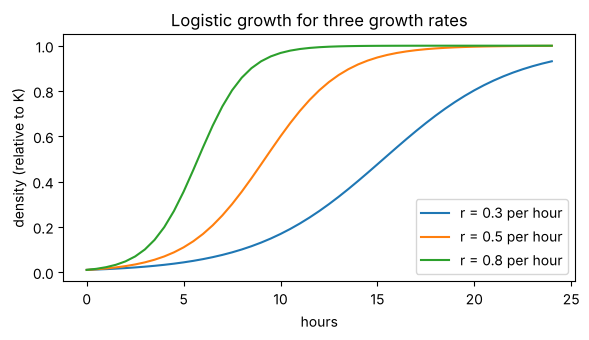

In [4]:
fig, ax = plt.subplots(figsize=(6, 3.5))
growth.plot(ax=ax)
ax.set_xlabel("hours")
ax.set_ylabel("density (relative to K)")
ax.set_title("Logistic growth for three growth rates")
fig.tight_layout()
plt.show()

## A file

The cell writes the table to `setup_check_output.csv` in this notebook's folder and reads it back. Your notebooks can save their results beside them in the same way.

In [5]:
output = Path("setup_check_output.csv")
growth.to_csv(output)
back = pd.read_csv(output, index_col="hours")
print(f"Wrote and read {output.name}: {len(back)} rows, {len(back.columns)} columns")
print("Same values as the table:", np.allclose(back.to_numpy(), growth.to_numpy()))

Wrote and read setup_check_output.csv: 49 rows, 3 columns
Same values as the table: True


## Done

If every cell above ran without an error, your computer is ready for the school.

In [6]:
print("Setup complete")

Setup complete
